# Preprocessing Bottleneck Sewing — Versi Terkoreksi

Notebook ini menggantikan perhitungan awal yang keliru pada TWC, beban operator, Line Efficiency, Balance Delay, dan Smoothing Index.

**Prinsip penting:**
- TWC dihitung dari jumlah CT rata-rata setiap aktivitas, bukan jumlah seluruh baris observasi.
- Beban operator tidak dihitung dengan menjumlahkan pengamatan berulang.
- SW16 diperlakukan sebagai dua server paralel (OP13 dan OP14) karena keduanya mengerjakan unit berbeda.
- Data produksi yang intervalnya berulang dipertahankan per baris dan tidak diagregasi sebelum makna baris dikonfirmasi.
- KPI hasil line balancing (LE, BD, SI) belum dihitung pada tahap preprocessing karena pembagian workstation belum tersedia.

Jalankan semua cell dari atas ke bawah. Upload file `Dataset_Bottleneck_Sewing_REVISED.xlsx` saat diminta.


In [ ]:
# 1. Upload file sumber
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError("Tidak ada file yang berhasil di-upload.")

input_file = list(uploaded.keys())[0]

print("File berhasil di-upload:", input_file)


Saving Dataset_Bottleneck_Sewing.xlsx to Dataset_Bottleneck_Sewing (1).xlsx
File berhasil di-upload: Dataset_Bottleneck_Sewing (1).xlsx


In [ ]:
import pandas as pd

xls = pd.ExcelFile(input_file)

print("Nama file:", input_file)
print("\nDaftar sheet yang tersedia:")

for sheet in xls.sheet_names:
    print("-", repr(sheet))

Nama file: Dataset_Bottleneck_Sewing (1).xlsx

Daftar sheet yang tersedia:
- '00_Petunjuk'
- '01_Master_Aktivitas'
- '02_Observasi_Waktu'
- '03_Data_Operator'
- '04_Data_Produksi'
- '05_Mesin_Stasiun'
- '06_Urutan_Proses'
- '07_Catatan_Metodologi'
- '08_Ringkasan_CT'
- '09_Matriks_Skill'
- '10_Validasi_Precedence'
- '11_Validasi_Kapasitas_Mesin'
- '12_Input_KPI_dan_Definisi'
- '13_Input_Optimasi'
- '14_Konfigurasi_Model'
- '15_Validasi_Data'
- '16_Rancangan_Algoritma'


In [ ]:
# 2. Import library dan baca sheet
import pandas as pd
import numpy as np
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

required_sheets = [
    "01_Master_Aktivitas", "02_Observasi_Waktu", "03_Data_Operator",
    "04_Data_Produksi", "05_Mesin_Stasiun", "06_Urutan_Proses"
]

xls = pd.ExcelFile(input_file)

missing = [s for s in required_sheets if s not in xls.sheet_names]

if missing:
    raise ValueError(f"Sheet wajib tidak ditemukan: {missing}")

master = pd.read_excel(input_file, sheet_name="01_Master_Aktivitas")
obs_raw = pd.read_excel(input_file, sheet_name="02_Observasi_Waktu")
operators = pd.read_excel(input_file, sheet_name="03_Data_Operator")
production = pd.read_excel(input_file, sheet_name="04_Data_Produksi")
machines = pd.read_excel(input_file, sheet_name="05_Mesin_Stasiun")
precedence = pd.read_excel(input_file, sheet_name="06_Urutan_Proses")

print("Sheet berhasil dibaca.")
print("Aktivitas:", master["ID_Aktivitas"].nunique())
print("Operator:", operators["ID_Operator"].nunique())
print("Baris observasi mentah:", len(obs_raw))

Sheet berhasil dibaca.
Aktivitas: 16
Operator: 14
Baris observasi mentah: 170


In [ ]:
# 3. Validasi kolom dan bersihkan observasi waktu
required_obs_cols = ["ID_Aktivitas", "ID_Operator", "Waktu_Proses_Detik"]
for col in required_obs_cols:
    if col not in obs_raw.columns:
        raise ValueError(f"Kolom wajib tidak ditemukan: {col}")

obs = obs_raw.copy()
obs["Waktu_Proses_Detik"] = pd.to_numeric(obs["Waktu_Proses_Detik"], errors="coerce")
obs = obs.dropna(subset=required_obs_cols)
obs = obs[obs["Waktu_Proses_Detik"] > 0].copy()

unknown_activities = sorted(set(obs["ID_Aktivitas"]) - set(master["ID_Aktivitas"]))
if unknown_activities:
    raise ValueError(f"Ada ID aktivitas yang tidak ada di master: {unknown_activities}")

print("Observasi valid:", len(obs))
print("Observasi dibuang:", len(obs_raw) - len(obs))


Observasi valid: 170
Observasi dibuang: 0


In [ ]:
# 4. Ringkasan CT per aktivitas dan per operator
ct_activity = (
    obs.groupby("ID_Aktivitas", as_index=False)
       .agg(Jumlah_Observasi=("Waktu_Proses_Detik", "count"),
            CT_Rata2_s=("Waktu_Proses_Detik", "mean"),
            CT_SD_s=("Waktu_Proses_Detik", "std"),
            CT_Min_s=("Waktu_Proses_Detik", "min"),
            CT_Max_s=("Waktu_Proses_Detik", "max"))
)
ct_activity = master[["ID_Aktivitas", "Nama_Aktivitas",
                      "Bisa_Dibagi (Ya/Tidak)", "Bisa_Paralel (Ya/Tidak)"]].merge(
    ct_activity, on="ID_Aktivitas", how="left", validate="one_to_one"
)

ct_operator = (
    obs.groupby(["ID_Aktivitas", "ID_Operator"], as_index=False)
       .agg(Jumlah_Observasi=("Waktu_Proses_Detik", "count"),
            CT_Rata2_s=("Waktu_Proses_Detik", "mean"),
            CT_SD_s=("Waktu_Proses_Detik", "std"),
            CT_Min_s=("Waktu_Proses_Detik", "min"),
            CT_Max_s=("Waktu_Proses_Detik", "max"))
)

display(ct_activity)
display(ct_operator)


,ID_Aktivitas,Nama_Aktivitas,Bisa_Dibagi (Ya/Tidak),Bisa_Paralel (Ya/Tidak),Jumlah_Observasi,CT_Rata2_s,CT_SD_s,CT_Min_s,CT_Max_s
0,SW01,Stitch Tongue Webbing & Tongue Overlay to Tong...,Tidak,Tidak,10,43.108,1.171113,41.15,44.55
1,SW02,Stitch & Turn Tongue Lining to Tongue / Jahit ...,Ya,Tidak,10,15.370,0.914598,14.08,16.56
2,SW03,Invert Tongue Lining / Balik Tongue Lining,Ya,Tidak,10,11.614,0.921040,10.05,13.11
3,SW04,Stitch Tongue Edge / Jahit Tepi Bawah Tongue,Tidak,Tidak,10,13.842,1.075637,11.26,15.31
4,SW05,Attach Collar Reinf Lat/Med / Tempel Collar Re...,Ya,Tidak,10,24.968,1.296241,23.08,26.56
5,SW06,Stitch & Turn Over Vamp/Quarter / Jahit & Bali...,Ya,Tidak,10,22.006,1.169570,20.24,23.53
6,SW07,Double Folding Vamp/Quarter / Double Folding V...,Ya,Tidak,10,12.945,1.253867,11.04,15.31
7,SW08,Hammering Heel Vamp/Quarter / Hammering Heel V...,Ya,Tidak,10,11.850,0.912213,10.04,13.05
8,SW09,Stitch Heel Tab to Upper / Jahit Heel Tab ke U...,Tidak,Tidak,10,43.106,1.172312,41.15,45.29
9,SW10,Stitch Collar Lining to Upper / Jahit Collar L...,Tidak,Tidak,10,42.649,1.193300,41.03,44.28


,ID_Aktivitas,ID_Operator,Jumlah_Observasi,CT_Rata2_s,CT_SD_s,CT_Min_s,CT_Max_s
0,SW01,OP01,10,43.108,1.171113,41.15,44.55
1,SW02,OP02,10,15.370,0.914598,14.08,16.56
2,SW03,OP02,10,11.614,0.921040,10.05,13.11
3,SW04,OP03,10,13.842,1.075637,11.26,15.31
4,SW05,OP04,10,24.968,1.296241,23.08,26.56
5,SW06,OP04,10,22.006,1.169570,20.24,23.53
6,SW07,OP05,10,12.945,1.253867,11.04,15.31
7,SW08,OP05,10,11.850,0.912213,10.04,13.05
8,SW09,OP06,10,43.106,1.172312,41.15,45.29
9,SW10,OP07,10,42.649,1.193300,41.03,44.28


In [ ]:
# 5. Bentuk matriks skill aktual
skill_col = "Level_Skill (0-3)"
if skill_col not in operators.columns:
    raise ValueError(f"Kolom skill tidak ditemukan: {skill_col}")

if operators.duplicated(["ID_Operator", "ID_Aktivitas"]).any():
    raise ValueError("Ada pasangan operator-aktivitas duplikat dalam data skill.")

skill_matrix = operators.pivot(
    index="ID_Operator", columns="ID_Aktivitas", values=skill_col
).sort_index()

print("Ukuran matriks skill:", skill_matrix.shape)
print("Nilai skill kosong:", int(skill_matrix.isna().sum().sum()))
display(skill_matrix)


Ukuran matriks skill: (14, 16)
Nilai skill kosong: 0


ID_Aktivitas,SW01,SW02,SW03,SW04,SW05,SW06,SW07,SW08,SW09,SW10,SW11,SW12,SW13,SW14,SW15,SW16
ID_Operator,,,,,,,,,,,,,,,,
OP01,3,2,2,3,2,2,1,3,1,1,1,1,2,1,2,1
OP02,3,3,2,3,2,2,1,2,1,2,1,1,1,1,2,1
OP03,3,2,2,2,1,2,3,2,1,1,1,1,1,2,1,2
OP04,3,2,1,2,3,2,1,1,2,1,1,1,1,2,1,2
OP05,2,2,2,3,2,1,2,2,1,1,1,1,2,1,1,1
OP06,1,1,1,2,3,2,2,2,2,2,1,1,1,2,2,2
OP07,2,2,2,2,2,2,3,2,2,3,1,1,2,1,1,2
OP08,1,1,2,2,1,2,2,3,1,1,2,2,1,2,1,2
OP09,1,1,1,1,2,1,2,2,1,1,2,2,1,2,1,2


In [ ]:
# 6. Baseline kapasitas dan perlakuan khusus SW16
TARGET_UNIT_PER_HOUR = 80
TAKT_TIME = 3600 / TARGET_UNIT_PER_HOUR

capacity_rows = []
for activity_id in master["ID_Aktivitas"]:
    act_ct = ct_activity.loc[ct_activity["ID_Aktivitas"] == activity_id, "CT_Rata2_s"].iloc[0]
    by_operator = ct_operator[ct_operator["ID_Aktivitas"] == activity_id]

    if activity_id == "SW16":
        # SW16: OP13 dan OP14 memproses unit berbeda secara paralel.
        if by_operator["ID_Operator"].nunique() != 2:
            raise ValueError("SW16 tidak memiliki tepat dua operator teramati; validasi data paralel.")
        capacity = (3600 / by_operator["CT_Rata2_s"]).sum()
        equivalent_ct = 3600 / capacity
        rule = "Kapasitas dua server paralel = jumlah kapasitas OP13 dan OP14"
    else:
        capacity = 3600 / act_ct
        equivalent_ct = act_ct
        rule = "Satu server; kapasitas = 3600 / CT rata-rata aktivitas"

    capacity_rows.append([
        activity_id, act_ct, capacity, equivalent_ct, rule
    ])

capacity = pd.DataFrame(
    capacity_rows,
    columns=["ID_Aktivitas", "CT_Rata2_Agregat_s",
             "Kapasitas_Teoritis_unit_jam",
             "CT_Ekuivalen_Kapasitas_s_unit", "Aturan_Perhitungan"]
)

capacity["Target_unit_jam"] = TARGET_UNIT_PER_HOUR
capacity["Memenuhi_Target_Teoritis"] = capacity["Kapasitas_Teoritis_unit_jam"] >= TARGET_UNIT_PER_HOUR

print(f"Takt time: {TAKT_TIME:.2f} detik/unit")
display(capacity.sort_values("Kapasitas_Teoritis_unit_jam"))


Takt time: 45.00 detik/unit


,ID_Aktivitas,CT_Rata2_Agregat_s,Kapasitas_Teoritis_unit_jam,CT_Ekuivalen_Kapasitas_s_unit,Aturan_Perhitungan,Target_unit_jam,Memenuhi_Target_Teoritis
0,SW01,43.108,83.511181,43.108000,Satu server; kapasitas = 3600 / CT rata-rata a...,80,True
8,SW09,43.106,83.515056,43.106000,Satu server; kapasitas = 3600 / CT rata-rata a...,80,True
10,SW11,42.757,84.196740,42.757000,Satu server; kapasitas = 3600 / CT rata-rata a...,80,True
9,SW10,42.649,84.409951,42.649000,Satu server; kapasitas = 3600 / CT rata-rata a...,80,True
11,SW12,38.647,93.150827,38.647000,Satu server; kapasitas = 3600 / CT rata-rata a...,80,True
15,SW16,68.450,105.884122,33.999432,Kapasitas dua server paralel = jumlah kapasita...,80,True
4,SW05,24.968,144.184556,24.968000,Satu server; kapasitas = 3600 / CT rata-rata a...,80,True
13,SW14,23.420,153.714774,23.420000,Satu server; kapasitas = 3600 / CT rata-rata a...,80,True
12,SW13,22.155,162.491537,22.155000,Satu server; kapasitas = 3600 / CT rata-rata a...,80,True
5,SW06,22.006,163.591748,22.006000,Satu server; kapasitas = 3600 / CT rata-rata a...,80,True


In [ ]:
# 7. Validasi precedence dan data produksi
known_activities = set(master["ID_Aktivitas"])
precedence["Pendahulu_valid"] = precedence["ID_Aktivitas_Pendahulu"].isin(known_activities)
precedence["Berikutnya_valid"] = precedence["ID_Aktivitas_Berikutnya"].isin(known_activities)
precedence["Self_loop"] = (
    precedence["ID_Aktivitas_Pendahulu"] == precedence["ID_Aktivitas_Berikutnya"]
)

# Cek apakah precedence membentuk graph tanpa siklus
try:
    import networkx as nx
    G = nx.DiGraph()
    G.add_nodes_from(known_activities)
    G.add_edges_from(zip(precedence["ID_Aktivitas_Pendahulu"],
                         precedence["ID_Aktivitas_Berikutnya"]))
    precedence_is_dag = nx.is_directed_acyclic_graph(G)
except ImportError:
    precedence_is_dag = None

interval_cols = ["Tanggal", "Shift", "Jam_Mulai", "Jam_Selesai", "Model_Style"]
available_interval_cols = [c for c in interval_cols if c in production.columns]
unique_intervals = production[available_interval_cols].drop_duplicates().shape[0]

print("Precedence membentuk DAG:", precedence_is_dag)
print("Baris produksi:", len(production))
print("Kombinasi interval unik:", unique_intervals)
print("Jangan agregasi data produksi sebelum arti 16 baris dikonfirmasi.")
display(precedence)


Precedence membentuk DAG: True
Baris produksi: 16
Kombinasi interval unik: 1
Jangan agregasi data produksi sebelum arti 16 baris dikonfirmasi.


,ID_Aktivitas_Pendahulu,ID_Aktivitas_Berikutnya,Jenis_Hubungan,Bukti/Konfirmasi,Keterangan,Pola_Alur,Status_Verifikasi,Dokumen_Bukti,Pendahulu_valid,Berikutnya_valid,Self_loop
0,SW01,SW02,Harus Sebelum,Hasil Observasi Langsung,SW01 harus selesai sebelum SW02 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False
1,SW02,SW03,Harus Sebelum,Hasil Observasi Langsung,SW02 harus selesai sebelum SW03 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False
2,SW03,SW04,Harus Sebelum,Hasil Observasi Langsung,SW03 harus selesai sebelum SW04 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False
3,SW04,SW05,Harus Sebelum,Hasil Observasi Langsung,SW04 harus selesai sebelum SW05 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False
4,SW05,SW06,Harus Sebelum,Hasil Observasi Langsung,SW05 harus selesai sebelum SW06 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False
5,SW06,SW07,Harus Sebelum,Hasil Observasi Langsung,SW06 harus selesai sebelum SW07 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False
6,SW07,SW08,Harus Sebelum,Hasil Observasi Langsung,SW07 harus selesai sebelum SW08 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False
7,SW08,SW09,Harus Sebelum,Hasil Observasi Langsung,SW08 harus selesai sebelum SW09 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False
8,SW09,SW10,Harus Sebelum,Hasil Observasi Langsung,SW09 harus selesai sebelum SW10 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False
9,SW10,SW11,Harus Sebelum,Hasil Observasi Langsung,SW10 harus selesai sebelum SW11 dimulai,Linear,Terverifikasi,SOP Sewing,True,True,False


In [ ]:
# 8. KPI yang boleh dan belum boleh dihitung pada tahap ini
total_work_content = ct_activity["CT_Rata2_s"].sum()

audit = pd.DataFrame([
    ["Jumlah aktivitas", master["ID_Aktivitas"].nunique()],
    ["Jumlah operator skill", operators["ID_Operator"].nunique()],
    ["Jumlah observasi waktu valid", len(obs)],
    ["Total Work Content (detik/unit)", total_work_content],
    ["Target produksi (unit/jam)", TARGET_UNIT_PER_HOUR],
    ["Takt Time (detik/unit)", TAKT_TIME],
    ["Kombinasi interval produksi unik", unique_intervals],
    ["Precedence DAG", precedence_is_dag],
], columns=["Indikator", "Nilai"])

print("TWC dihitung dari jumlah CT rata-rata per aktivitas.")
print("Line Efficiency, Balance Delay, dan Smoothing Index TIDAK dihitung di tahap ini.")
print("Ketiganya baru dihitung setelah alokasi aktivitas ke workstation selesai.")
display(audit)


TWC dihitung dari jumlah CT rata-rata per aktivitas.
Line Efficiency, Balance Delay, dan Smoothing Index TIDAK dihitung di tahap ini.
Ketiganya baru dihitung setelah alokasi aktivitas ke workstation selesai.


,Indikator,Nilai
0,Jumlah aktivitas,16
1,Jumlah operator skill,14
2,Jumlah observasi waktu valid,170
3,Total Work Content (detik/unit),458.258
4,Target produksi (unit/jam),80
5,Takt Time (detik/unit),45.0
6,Kombinasi interval produksi unik,1
7,Precedence DAG,True


In [ ]:
# 9. Ekspor dataset preprocessing yang tervalidasi
output_file = "Preprocessing_Bottleneck_Sewing_CORRECTED.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    ct_activity.to_excel(writer, sheet_name="01_CT_Aktivitas", index=False)
    ct_operator.to_excel(writer, sheet_name="02_CT_Operator", index=False)
    skill_matrix.to_excel(writer, sheet_name="03_Matriks_Skill")
    precedence.to_excel(writer, sheet_name="04_Precedence", index=False)
    capacity.to_excel(writer, sheet_name="05_Kapasitas_Baseline", index=False)
    production.to_excel(writer, sheet_name="06_Produksi_Raw", index=False)
    machines.to_excel(writer, sheet_name="07_Resource_Mesin", index=False)
    audit.to_excel(writer, sheet_name="08_Audit_Data", index=False)
    obs.to_excel(writer, sheet_name="09_Observasi_Clean", index=False)

# Format workbook
wb = load_workbook(output_file)
for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="1F4E78")
        cell.alignment = Alignment(wrap_text=True, vertical="center")
    ws.row_dimensions[1].height = 30
    for col in ws.columns:
        max_len = max((len(str(c.value)) if c.value is not None else 0) for c in col)
        ws.column_dimensions[get_column_letter(col[0].column)].width = min(max(max_len + 2, 12), 55)
wb.save(output_file)

files.download(output_file)
print("Selesai:", output_file)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Selesai: Preprocessing_Bottleneck_Sewing_CORRECTED.xlsx


In [ ]:
from google.colab import files

uploaded = files.upload()

if not uploaded:
    raise ValueError("Tidak ada file yang berhasil di-upload.")

input_file = list(uploaded.keys())[0]

print("File berhasil di-upload:", input_file)

Saving Preprocessing_Bottleneck_Sewing_CORRECTED (2).xlsx to Preprocessing_Bottleneck_Sewing_CORRECTED (2).xlsx
File berhasil di-upload: Preprocessing_Bottleneck_Sewing_CORRECTED (2).xlsx


In [ ]:

import pandas as pd
import numpy as np

# 1. Baca workbook preprocessing
file_path = "/content/Preprocessing_Bottleneck_Sewing_CORRECTED (2).xlsx"

df_ct = pd.read_excel(
    file_path,
    sheet_name="01_CT_Aktivitas"
)

# 2. Ambil aktivitas SW01-SW15
df_rpw = df_ct[
    df_ct["ID_Aktivitas"].isin(
        [f"SW{i:02d}" for i in range(1, 16)]
    )
].copy()

# 3. Urutkan aktivitas
df_rpw["Urutan"] = (
    df_rpw["ID_Aktivitas"].str.extract(r"(\d+)").astype(int)
)

df_rpw = df_rpw.sort_values("Urutan").reset_index(drop=True)

# 4. Hitung positional weight
df_rpw["Positional_Weight"] = (
    df_rpw["CT_Rata2_s"][::-1].cumsum()[::-1].values
)

# 5. Ranking RPW
df_rpw["Rank_RPW"] = (
    df_rpw["Positional_Weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# 6. Tampilkan hasil
hasil_rpw = df_rpw[
    [
        "ID_Aktivitas",
        "CT_Rata2_s",
        "Positional_Weight",
        "Rank_RPW"
    ]
]

print(hasil_rpw.to_string(index=False))


ID_Aktivitas  CT_Rata2_s  Positional_Weight  Rank_RPW
        SW01      43.108            389.808         1
        SW02      15.370            346.700         2
        SW03      11.614            331.330         3
        SW04      13.842            319.716         4
        SW05      24.968            305.874         5
        SW06      22.006            280.906         6
        SW07      12.945            258.900         7
        SW08      11.850            245.955         8
        SW09      43.106            234.105         9
        SW10      42.649            190.999        10
        SW11      42.757            148.350        11
        SW12      38.647            105.593        12
        SW13      22.155             66.946        13
        SW14      23.420             44.791        14
        SW15      21.371             21.371        15


In [ ]:

import pandas as pd
import numpy as np
import itertools
from scipy.optimize import linear_sum_assignment

# ==========================================
# 1. BACA DATA WORKBOOK
# ==========================================

file_path = "/content/Preprocessing_Bottleneck_Sewing_CORRECTED (2).xlsx"

df_ct = pd.read_excel(
    file_path,
    sheet_name="01_CT_Aktivitas"
)

df_skill = pd.read_excel(
    file_path,
    sheet_name="03_Matriks_Skill"
)

# Ambil aktivitas SW01-SW15
df_ct = df_ct[
    df_ct["ID_Aktivitas"].isin(
        [f"SW{i:02d}" for i in range(1, 16)]
    )
].copy()

df_ct["Urutan"] = (
    df_ct["ID_Aktivitas"]
    .str.extract(r"(\d+)")
    .astype(int)
)

df_ct = df_ct.sort_values("Urutan").reset_index(drop=True)

activities = df_ct["ID_Aktivitas"].tolist()
ct = dict(zip(
    df_ct["ID_Aktivitas"],
    df_ct["CT_Rata2_s"]
))

# ==========================================
# 2. HITUNG POSITIONAL WEIGHT
# ==========================================

df_ct["Positional_Weight"] = (
    df_ct["CT_Rata2_s"][::-1].cumsum()[::-1].values
)

df_ct["Rank_RPW"] = (
    df_ct["Positional_Weight"]
    .rank(method="first", ascending=False)
    .astype(int)
)

# ==========================================
# 3. SIAPKAN MATRIKS SKILL OP01-OP12
# ==========================================

df_skill = df_skill.set_index("ID_Operator")

operators = [f"OP{i:02d}" for i in range(1, 13)]

skill = df_skill.loc[operators, activities]

# ==========================================
# 4. ENUMERASI PEMBAGIAN 15 AKTIVITAS
#    MENJADI 12 KELOMPOK BERURUTAN
# ==========================================

best_result = None
all_feasible = []

target_time = 45

# 12 kelompok membutuhkan 11 batas pemisah
for cuts in itertools.combinations(range(1, 15), 11):

    boundaries = (0,) + cuts + (15,)

    groups = [
        activities[boundaries[i]:boundaries[i+1]]
        for i in range(12)
    ]

    # Total CT setiap kelompok
    loads = [
        sum(ct[a] for a in group)
        for group in groups
    ]

    # Batas takt time
    if max(loads) > target_time:
        continue

    # ======================================
    # 5. HITUNG SKOR SKILL SETIAP KELOMPOK
    #    TERHADAP SETIAP OPERATOR
    # ======================================

    score_matrix = np.array([
        [
            sum(skill.loc[op, activity] for activity in group)
            for op in operators
        ]
        for group in groups
    ])

    # Hungarian: maksimalkan skor skill
    row_ind, col_ind = linear_sum_assignment(
        -score_matrix
    )

    total_skill = int(
        score_matrix[row_ind, col_ind].sum()
    )

    max_ct = max(loads)

    candidate = {
        "max_ct": max_ct,
        "total_skill": total_skill,
        "groups": groups,
        "loads": loads,
        "assignment": list(zip(row_ind, col_ind)),
        "score_matrix": score_matrix
    }

    all_feasible.append(candidate)

    # Prioritas 1: maksimum CT terkecil
    # Prioritas 2: skor skill terbesar
    if (
        best_result is None
        or max_ct < best_result["max_ct"] - 1e-9
        or (
            abs(max_ct - best_result["max_ct"]) < 1e-9
            and total_skill > best_result["total_skill"]
        )
    ):
        best_result = candidate

# ==========================================
# 6. TAMPILKAN HASIL ASSIGNMENT
# ==========================================

if best_result is None:
    print("Tidak ditemukan pembagian yang memenuhi takt time.")
else:
    output = []

    for group_idx, op_idx in best_result["assignment"]:

        group = best_result["groups"][group_idx]
        operator = operators[op_idx]

        skill_values = [
            int(skill.loc[operator, a])
            for a in group
        ]

        output.append({
            "Operator": operator,
            "Aktivitas": " - ".join(group),
            "Total_CT_s": round(
                best_result["loads"][group_idx], 3
            ),
            "Skill": " - ".join(map(str, skill_values)),
            "Skor_Skill": sum(skill_values)
        })

    df_assignment = pd.DataFrame(output)

    df_assignment = df_assignment.sort_values(
        "Operator"
    ).reset_index(drop=True)

    print("HASIL ASSIGNMENT RPW")
    print(df_assignment.to_string(index=False))

    print("\nMAKSIMUM CT:",
          round(best_result["max_ct"], 3), "detik")

    print("TOTAL SKILL:",
          best_result["total_skill"])

    print("JUMLAH OPERATOR:",
          len(df_assignment))

    print("JUMLAH KOMBINASI LAYAK:",
          len(all_feasible))

    # SW16 dipisahkan sebagai stasiun paralel
    ct_op13 = 74.007
    ct_op14 = 62.893

    capacity_sw16 = (
        3600 / ct_op13 + 3600 / ct_op14
    )

    ct_equivalent_sw16 = 3600 / capacity_sw16

    print("\nSTASIUN SW16")
    print("OP13 CT:", ct_op13)
    print("OP14 CT:", ct_op14)
    print("Kapasitas gabungan:",
          round(capacity_sw16, 3), "pair/jam")
    print("CT ekuivalen:",
          round(ct_equivalent_sw16, 3), "detik/pair")

    # Simpan hasil
    df_assignment.to_excel(
        "/content/Hasil_Assignment_RPW.xlsx",
        index=False
    )

    print("\nFile berhasil disimpan:")
    print("Hasil_Assignment_RPW.xlsx")


HASIL ASSIGNMENT RPW
Operator   Aktivitas  Total_CT_s Skill  Skor_Skill
    OP01        SW15      21.371     2           2
    OP02 SW02 - SW03      26.984 3 - 2           5
    OP03 SW06 - SW07      34.951 2 - 3           5
    OP04        SW01      43.108     3           3
    OP05 SW04 - SW05      38.810 3 - 2           5
    OP06        SW09      43.106     2           2
    OP07        SW10      42.649     3           3
    OP08        SW08      11.850     3           3
    OP09        SW11      42.757     2           2
    OP10        SW13      22.155     3           3
    OP11        SW14      23.420     2           2
    OP12        SW12      38.647     2           2

MAKSIMUM CT: 43.108 detik
TOTAL SKILL: 37
JUMLAH OPERATOR: 12
JUMLAH KOMBINASI LAYAK: 12

STASIUN SW16
OP13 CT: 74.007
OP14 CT: 62.893
Kapasitas gabungan: 105.884 pair/jam
CT ekuivalen: 33.999 detik/pair

File berhasil disimpan:
Hasil_Assignment_RPW.xlsx


In [ ]:

!pip -q install openpyxl scipy

import pandas as pd
import numpy as np
import random
import itertools
import os

from scipy.optimize import linear_sum_assignment
from google.colab import files

random.seed(42)
np.random.seed(42)

print("Library berhasil diimpor.")


Library berhasil diimpor.


In [ ]:

uploaded = files.upload()

input_file = next(
    name for name in uploaded.keys()
    if name.lower().endswith((".xlsx", ".xls"))
)

# Baca data CT
df_ct = pd.read_excel(
    input_file,
    sheet_name="01_CT_Aktivitas"
)

# Baca matriks skill
df_skill = pd.read_excel(
    input_file,
    sheet_name="03_Matriks_Skill"
)

# Validasi kolom
required_ct = ["ID_Aktivitas", "CT_Rata2_s"]
required_skill = ["ID_Operator"]

for col in required_ct:
    if col not in df_ct.columns:
        raise ValueError(f"Kolom CT tidak ditemukan: {col}")

for col in required_skill:
    if col not in df_skill.columns:
        raise ValueError(f"Kolom skill tidak ditemukan: {col}")

# Aktivitas SW01-SW15
activities = [f"SW{i:02d}" for i in range(1, 16)]

df_ct = df_ct[
    df_ct["ID_Aktivitas"].isin(activities)
].copy()

df_ct["ID_Aktivitas"] = pd.Categorical(
    df_ct["ID_Aktivitas"],
    categories=activities,
    ordered=True
)

df_ct = df_ct.sort_values("ID_Aktivitas")

ct = dict(zip(
    df_ct["ID_Aktivitas"].astype(str),
    pd.to_numeric(df_ct["CT_Rata2_s"], errors="raise")
))

# Operator OP01-OP12
operators = [f"OP{i:02d}" for i in range(1, 13)]

df_skill = df_skill.set_index("ID_Operator")

skill = df_skill.loc[operators, activities].apply(
    pd.to_numeric, errors="raise"
)

if skill.isna().any().any():
    raise ValueError("Matriks skill mengandung nilai kosong.")

if set(ct.keys()) != set(activities):
    raise ValueError("Data CT tidak lengkap untuk SW01-SW15.")

print("Dataset berhasil dibaca.")
print("Jumlah aktivitas:", len(activities))
print("Jumlah operator:", len(operators))
print("Total CT:", round(sum(ct.values()), 3))


Saving Preprocessing_Bottleneck_Sewing_CORRECTED (3).xlsx to Preprocessing_Bottleneck_Sewing_CORRECTED (3).xlsx
Dataset berhasil dibaca.
Jumlah aktivitas: 15
Jumlah operator: 12
Total CT: 389.808


In [ ]:

# =====================================
# PARAMETER GENETIC SEARCH
# =====================================

POP_SIZE = 100
GENERATIONS = 300

CROSSOVER_RATE = 0.80
MUTATION_RATE = 0.20

ELITE_SIZE = 5
TOURNAMENT_SIZE = 3

TARGET_CT = 45.0

# Jumlah batas pemisah:
# 15 aktivitas menjadi 12 kelompok
N_CUTS = 11

print("Parameter Genetic Search siap.")


Parameter Genetic Search siap.


In [ ]:

# =====================================
# REPRESENTASI KROMOSOM
# =====================================

def random_chromosome():

    chrom = np.zeros(14, dtype=int)

    selected = random.sample(range(14), N_CUTS)

    chrom[selected] = 1

    return chrom


def decode_chromosome(chrom):

    cuts = [
        i + 1
        for i, value in enumerate(chrom)
        if value == 1
    ]

    boundaries = [0] + cuts + [15]

    groups = []

    for i in range(12):

        group = activities[
            boundaries[i]:boundaries[i+1]
        ]

        groups.append(group)

    return groups


# Validasi
test_chrom = random_chromosome()
test_groups = decode_chromosome(test_chrom)

print("Jumlah kelompok:", len(test_groups))
print("Jumlah aktivitas:",
      sum(len(g) for g in test_groups))


Jumlah kelompok: 12
Jumlah aktivitas: 15


In [ ]:



# =====================================
# EVALUASI KROMOSOM
# FITNESS DENGAN BATASAN SKILL
# =====================================

MIN_TOTAL_SKILL = 37

def evaluate_chromosome(chrom):

    groups = decode_chromosome(chrom)

    # Total CT setiap kelompok
    loads = np.array([
        sum(ct[a] for a in group)
        for group in groups
    ], dtype=float)

    max_ct = float(np.max(loads))
    min_ct = float(np.min(loads))
    mean_ct = float(np.mean(loads))

    std_ct = float(np.std(loads, ddof=0))

    cv = (
        std_ct / mean_ct * 100
        if mean_ct > 0 else 0
    )

    # Validasi target CT
    ct_feasible = max_ct <= TARGET_CT + 1e-9
    ct_violation = max(0, max_ct - TARGET_CT)

    # Matriks skor skill
    score_matrix = np.array([
        [
            sum(
                float(skill.loc[op, activity])
                for activity in group
            )
            for op in operators
        ]
        for group in groups
    ])

    # Hungarian Algorithm
    row_ind, col_ind = linear_sum_assignment(
        -score_matrix
    )

    total_skill = int(
        score_matrix[row_ind, col_ind].sum()
    )

    # Validasi minimum skill
    skill_feasible = total_skill >= MIN_TOTAL_SKILL
    skill_shortfall = max(
        0,
        MIN_TOTAL_SKILL - total_skill
    )

    feasible = ct_feasible and skill_feasible

    # Fitness lexicographic
    fitness = (
        0 if ct_feasible else 1,
        round(ct_violation, 8),
        0 if skill_feasible else 1,
        skill_shortfall,
        round(std_ct, 8),
        round(max_ct, 8),
        -total_skill
    )

    return {
        "groups": groups,
        "loads": loads.tolist(),
        "max_ct": max_ct,
        "min_ct": min_ct,
        "mean_ct": mean_ct,
        "std_ct": std_ct,
        "cv": cv,
        "total_skill": total_skill,
        "feasible": feasible,
        "ct_feasible": ct_feasible,
        "skill_feasible": skill_feasible,
        "assignment": list(zip(row_ind, col_ind)),
        "fitness": fitness
    }

print("Fitness dengan batasan skill berhasil diperbarui.")
print("Target CT:", TARGET_CT)
print("Minimum total skill:", MIN_TOTAL_SKILL)



Fitness dengan batasan skill berhasil diperbarui.
Target CT: 45.0
Minimum total skill: 37


In [ ]:

# =====================================
# TOURNAMENT SELECTION
# =====================================

def selection(population, evaluations):

    candidates = random.sample(
        range(len(population)),
        TOURNAMENT_SIZE
    )

    winner = min(
        candidates,
        key=lambda i: evaluations[i]["fitness"]
    )

    return population[winner].copy()


# =====================================
# CROSSOVER
# =====================================

def repair_chromosome(chrom):

    chrom = np.array(chrom, dtype=int).copy()

    ones = np.where(chrom == 1)[0]
    zeros = np.where(chrom == 0)[0]

    if len(ones) > N_CUTS:

        remove = random.sample(
            list(ones),
            len(ones) - N_CUTS
        )

        chrom[remove] = 0

    elif len(ones) < N_CUTS:

        add = random.sample(
            list(zeros),
            N_CUTS - len(ones)
        )

        chrom[add] = 1

    return chrom


def crossover(parent1, parent2):

    if random.random() > CROSSOVER_RATE:

        return parent1.copy(), parent2.copy()

    mask = np.random.randint(
        0, 2, size=14
    )

    child1 = np.where(
        mask == 1,
        parent1,
        parent2
    )

    child2 = np.where(
        mask == 1,
        parent2,
        parent1
    )

    child1 = repair_chromosome(child1)
    child2 = repair_chromosome(child2)

    return child1, child2


# =====================================
# MUTATION
# =====================================

def mutation(chrom):

    chrom = chrom.copy()

    if random.random() < MUTATION_RATE:

        ones = np.where(chrom == 1)[0]
        zeros = np.where(chrom == 0)[0]

        remove = random.choice(list(ones))
        add = random.choice(list(zeros))

        chrom[remove] = 0
        chrom[add] = 1

    return chrom


In [ ]:

# =====================================
# BASELINE RPW
# =====================================

baseline_groups = [
    ["SW01"],
    ["SW02", "SW03"],
    ["SW04", "SW05"],
    ["SW06", "SW07"],
    ["SW08"],
    ["SW09"],
    ["SW10"],
    ["SW11"],
    ["SW12"],
    ["SW13"],
    ["SW14"],
    ["SW15"]
]

def encode_groups(groups):

    chrom = np.zeros(14, dtype=int)

    cumulative = 0

    for group in groups[:-1]:

        cumulative += len(group)

        chrom[cumulative - 1] = 1

    return chrom


baseline_chrom = encode_groups(baseline_groups)

baseline_eval = evaluate_chromosome(baseline_chrom)

# =====================================
# INISIALISASI POPULASI
# =====================================

population = [
    baseline_chrom.copy()
]

while len(population) < POP_SIZE:

    population.append(random_chromosome())


best_global = None
history = []

# =====================================
# PROSES EVOLUSI
# =====================================

for generation in range(GENERATIONS):

    evaluations = [
        evaluate_chromosome(chrom)
        for chrom in population
    ]

    # Urutkan berdasarkan fitness
    sorted_indices = sorted(
        range(len(population)),
        key=lambda i: evaluations[i]["fitness"]
    )

    population = [
        population[i].copy()
        for i in sorted_indices
    ]

    evaluations = [
        evaluations[i]
        for i in sorted_indices
    ]

    current_best = evaluations[0]

    if (
        best_global is None
        or current_best["fitness"] < best_global["fitness"]
    ):

        best_global = current_best.copy()

        best_global["chromosome"] = (
            population[0].copy()
        )

    history.append({

        "Generation": generation + 1,

        "Best_Max_CT": current_best["max_ct"],

        "Best_Skill": current_best["total_skill"],

        "Feasible": current_best["feasible"]

    })

    # Elitism
    new_population = [
        population[i].copy()
        for i in range(ELITE_SIZE)
    ]

    # Membuat generasi baru
    while len(new_population) < POP_SIZE:

        parent1 = selection(
            population,
            evaluations
        )

        parent2 = selection(
            population,
            evaluations
        )

        child1, child2 = crossover(
            parent1,
            parent2
        )

        child1 = mutation(child1)
        child2 = mutation(child2)

        new_population.append(child1)

        if len(new_population) < POP_SIZE:
            new_population.append(child2)

    population = new_population

    if (generation + 1) % 50 == 0:

        print(
            f"Generasi {generation+1}: "
            f"Max CT = {current_best['max_ct']:.3f}, "
            f"Skill = {current_best['total_skill']}"
        )


print("\nGENETIC SEARCH SELESAI")

print(
    "Best Max CT:",
    round(best_global["max_ct"], 3)
)

print(
    "Best Skill:",
    best_global["total_skill"]
)

print(
    "Feasible:",
    best_global["feasible"]
)


Generasi 50: Max CT = 43.108, Skill = 37
Generasi 100: Max CT = 43.108, Skill = 37
Generasi 150: Max CT = 43.108, Skill = 37
Generasi 200: Max CT = 43.108, Skill = 37
Generasi 250: Max CT = 43.108, Skill = 37
Generasi 300: Max CT = 43.108, Skill = 37

GENETIC SEARCH SELESAI
Best Max CT: 43.108
Best Skill: 37
Feasible: True


In [ ]:

# =====================================
# PENGUJIAN GENETIC ALGORITHM
# DENGAN 10 RANDOM SEED
# =====================================

def run_ga(seed):

    random.seed(seed)
    np.random.seed(seed)

    # Inisialisasi populasi
    population = [baseline_chrom.copy()]

    while len(population) < POP_SIZE:
        population.append(random_chromosome())

    best_global_seed = None

    for generation in range(GENERATIONS):

        evaluations = [
            evaluate_chromosome(chrom)
            for chrom in population
        ]

        # Urutkan berdasarkan fitness
        sorted_indices = sorted(
            range(len(population)),
            key=lambda i: evaluations[i]["fitness"]
        )

        population = [
            population[i].copy()
            for i in sorted_indices
        ]

        evaluations = [
            evaluations[i]
            for i in sorted_indices
        ]

        current_best = evaluations[0]

        if (
            best_global_seed is None
            or current_best["fitness"]
            < best_global_seed["fitness"]
        ):
            best_global_seed = current_best.copy()
            best_global_seed["chromosome"] = population[0].copy()

        # Elitism
        new_population = [
            population[i].copy()
            for i in range(ELITE_SIZE)
        ]

        # Membuat generasi baru
        while len(new_population) < POP_SIZE:

            parent1 = selection(population, evaluations)
            parent2 = selection(population, evaluations)

            child1, child2 = crossover(parent1, parent2)

            child1 = mutation(child1)
            child2 = mutation(child2)

            new_population.append(child1)

            if len(new_population) < POP_SIZE:
                new_population.append(child2)

        population = new_population

    return best_global_seed


# =====================================
# JALANKAN 10 RANDOM SEED
# =====================================

seeds = list(range(1, 11))

results_seed = []

for seed in seeds:

    result = run_ga(seed)

    results_seed.append({
        "Seed": seed,
        "Max_CT": result["max_ct"],
        "Min_CT": result["min_ct"],
        "Std_Dev": result["std_ct"],
        "CV": result["cv"],
        "Total_Skill": result["total_skill"],
        "Feasible": result["feasible"],
        "Fitness": result["fitness"],
        "Result": result
    })

    print(
        f"Seed {seed}: "
        f"Max CT = {result['max_ct']:.3f}, "
        f"Std = {result['std_ct']:.3f}, "
        f"Skill = {result['total_skill']}, "
        f"Feasible = {result['feasible']}"
    )


# =====================================
# TABEL HASIL PENGUJIAN
# =====================================

df_seed = pd.DataFrame([
    {k: v for k, v in row.items()
     if k not in ["Fitness", "Result"]}
    for row in results_seed
])

print("\n=== HASIL PENGUJIAN 10 RANDOM SEED ===")
display(df_seed.round(3))


# =====================================
# MEMILIH HASIL TERBAIK
# =====================================

best_run = min(
    results_seed,
    key=lambda x: x["Fitness"]
)

best_global = best_run["Result"]

print("\n=== HASIL TERBAIK DARI 10 RANDOM SEED ===")
print("Seed terbaik:", best_run["Seed"])
print("Maximum CT:", round(best_global["max_ct"], 3))
print("Minimum CT:", round(best_global["min_ct"], 3))
print("Standar deviasi:", round(best_global["std_ct"], 3))
print("Total skill:", best_global["total_skill"])
print("Feasible:", best_global["feasible"])


Seed 1: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True
Seed 2: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True
Seed 3: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True
Seed 4: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True
Seed 5: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True
Seed 6: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True
Seed 7: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True
Seed 8: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True
Seed 9: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True
Seed 10: Max CT = 43.108, Std = 10.356, Skill = 37, Feasible = True

=== HASIL PENGUJIAN 10 RANDOM SEED ===


,Seed,Max_CT,Min_CT,Std_Dev,CV,Total_Skill,Feasible
0,1,43.108,11.85,10.356,31.881,37,True
1,2,43.108,11.85,10.356,31.881,37,True
2,3,43.108,11.85,10.356,31.881,37,True
3,4,43.108,11.85,10.356,31.881,37,True
4,5,43.108,11.85,10.356,31.881,37,True
5,6,43.108,11.85,10.356,31.881,37,True
6,7,43.108,11.85,10.356,31.881,37,True
7,8,43.108,11.85,10.356,31.881,37,True
8,9,43.108,11.85,10.356,31.881,37,True
9,10,43.108,11.85,10.356,31.881,37,True



=== HASIL TERBAIK DARI 10 RANDOM SEED ===
Seed terbaik: 1
Maximum CT: 43.108
Minimum CT: 11.85
Standar deviasi: 10.356
Total skill: 37
Feasible: True


In [ ]:

# =====================================
# MEMBUAT TABEL HASIL GS
# =====================================

def create_assignment_table(result):

    output = []

    for group_idx, operator_idx in result["assignment"]:

        group = result["groups"][group_idx]

        op = operators[operator_idx]

        skill_values = [
            int(skill.loc[op, activity])
            for activity in group
        ]

        output.append({

            "Operator": op,

            "Aktivitas": " - ".join(group),

            "Total_CT_s": round(
                result["loads"][group_idx], 3
            ),

            "Skill": " - ".join(
                map(str, skill_values)
            ),

            "Skor_Skill": sum(skill_values)

        })

    return pd.DataFrame(output).sort_values(
        "Operator"
    ).reset_index(drop=True)


df_gs = create_assignment_table(best_global)

print("HASIL ASSIGNMENT GENETIC SEARCH")

print(df_gs.to_string(index=False))

print("\nMaksimum CT:",
      round(best_global["max_ct"], 3))

print("Total Skill:",
      best_global["total_skill"])

print("Jumlah Operator:",
      len(df_gs))


HASIL ASSIGNMENT GENETIC SEARCH
Operator   Aktivitas  Total_CT_s Skill  Skor_Skill
    OP01        SW15      21.371     2           2
    OP02 SW02 - SW03      26.984 3 - 2           5
    OP03 SW06 - SW07      34.951 2 - 3           5
    OP04        SW01      43.108     3           3
    OP05 SW04 - SW05      38.810 3 - 2           5
    OP06        SW09      43.106     2           2
    OP07        SW10      42.649     3           3
    OP08        SW08      11.850     3           3
    OP09        SW11      42.757     2           2
    OP10        SW13      22.155     3           3
    OP11        SW14      23.420     2           2
    OP12        SW12      38.647     2           2

Maksimum CT: 43.108
Total Skill: 37
Jumlah Operator: 12


=== HASIL ASSIGNMENT GA TERBARU ===
Operator   Aktivitas     CT Skill  Skor_Skill
    OP01        SW15 21.371     2           2
    OP02 SW02 - SW03 26.984 3 - 2           5
    OP03 SW06 - SW07 34.951 2 - 3           5
    OP04        SW01 43.108     3           3
    OP05 SW04 - SW05 38.810 3 - 2           5
    OP06        SW09 43.106     2           2
    OP07        SW10 42.649     3           3
    OP08        SW08 11.850     3           3
    OP09        SW11 42.757     2           2
    OP10        SW13 22.155     3           3
    OP11        SW14 23.420     2           2
    OP12        SW12 38.647     2           2

Rata-rata CT: 32.484
Maksimum CT: 43.108
Minimum CT: 11.85


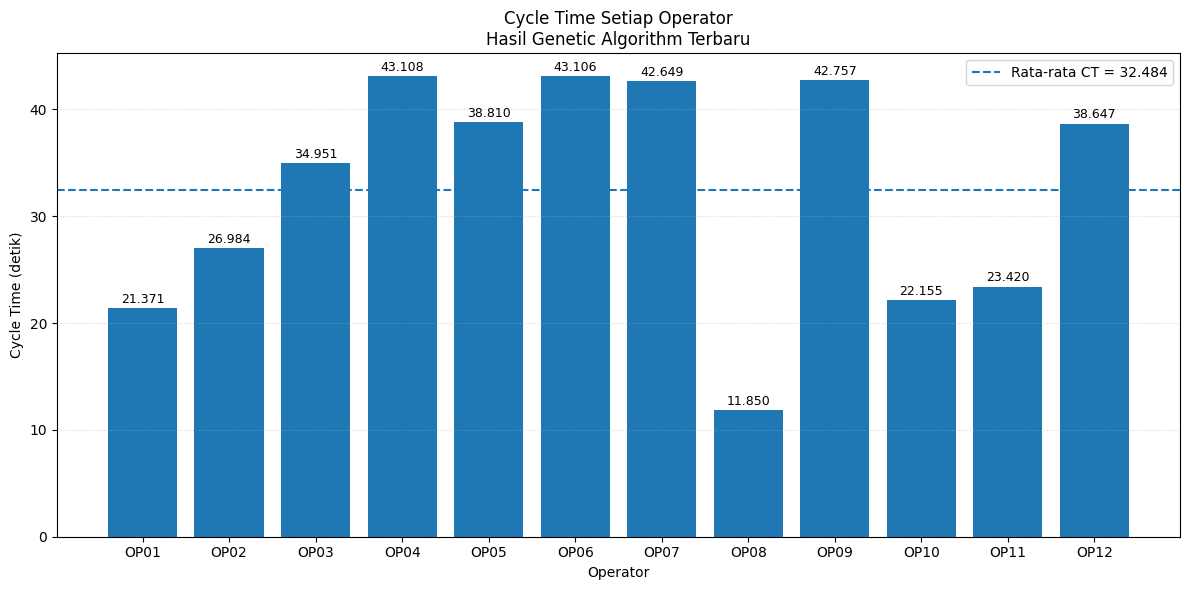

In [ ]:


# ==========================================
# DATA HASIL GENETIC ALGORITHM TERBARU
# ==========================================

df = df_gs.copy()

df = df.rename(columns={
    "Total_CT_s": "CT"
})

# Statistik beban kerja terbaru
rata_ct = df["CT"].mean()
maks_ct = df["CT"].max()
min_ct = df["CT"].min()

print("=== HASIL ASSIGNMENT GA TERBARU ===")
print(df.to_string(index=False))

print("\nRata-rata CT:", round(rata_ct, 3))
print("Maksimum CT:", round(maks_ct, 3))
print("Minimum CT:", round(min_ct, 3))

# ==========================================
# GRAFIK CYCLE TIME OPERATOR
# ==========================================

plt.figure(figsize=(12, 6))

plt.bar(df["Operator"], df["CT"])

plt.axhline(
    y=rata_ct,
    linestyle="--",
    label=f"Rata-rata CT = {rata_ct:.3f}"
)

for i, value in enumerate(df["CT"]):
    plt.text(
        i, value + 0.5,
        f"{value:.3f}",
        ha="center",
        fontsize=9
    )

plt.title(
    "Cycle Time Setiap Operator\n"
    "Hasil Genetic Algorithm Terbaru"
)

plt.xlabel("Operator")
plt.ylabel("Cycle Time (detik)")
plt.legend()
plt.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()



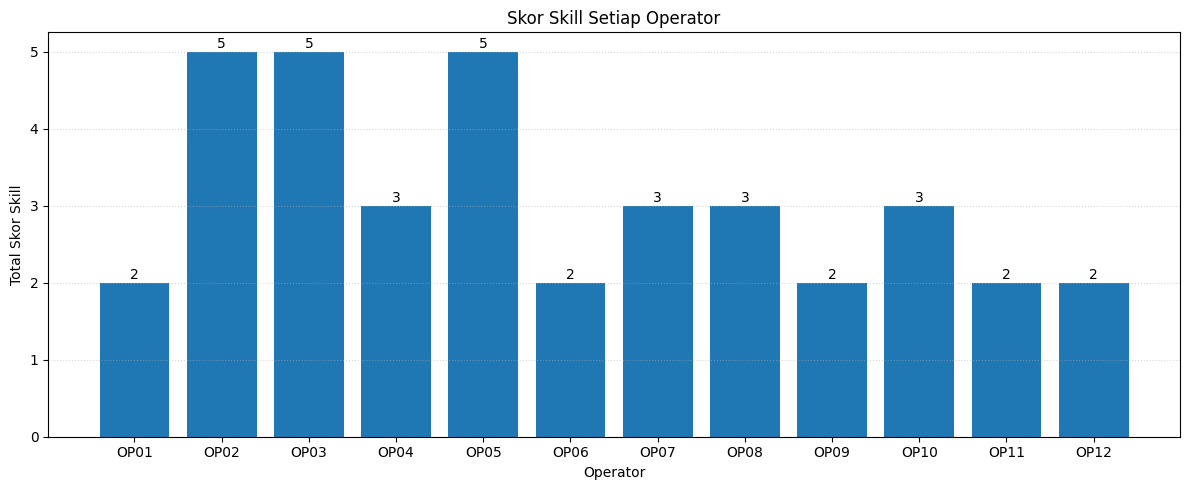

In [ ]:

plt.figure(figsize=(12, 5))

plt.bar(
    df['Operator'],
    df['Skor_Skill']
)

for i, value in enumerate(df['Skor_Skill']):
    plt.text(i, value + 0.05, str(value),
             ha='center')

plt.title('Skor Skill Setiap Operator')
plt.xlabel('Operator')
plt.ylabel('Total Skor Skill')
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# EVALUASI KESEIMBANGAN BEBAN KERJA OPERATOR
# ==========================================

N = len(df)

total_ct = df['CT'].sum()
ct_max = df['CT'].max()
ct_min = df['CT'].min()
rata_ct = df['CT'].mean()

# Line Efficiency
line_efficiency = (total_ct / (N * ct_max)) * 100

# Balance Delay
balance_delay = 100 - line_efficiency

# Smoothness Index
smoothness_index = np.sqrt(
    np.sum((ct_max - df['CT']) ** 2)
)

# Standar Deviasi
standar_deviasi = df['CT'].std(ddof=0)

# Coefficient of Variation
cv = (standar_deviasi / rata_ct) * 100

# Range
range_ct = ct_max - ct_min

# Menampilkan hasil
print("======================================")
print(" HASIL EVALUASI GENETIC ALGORITHM")
print("======================================")
print(f"Jumlah Operator       : {N}")
print(f"Total CT              : {total_ct:.3f}")
print(f"Rata-rata CT          : {rata_ct:.3f}")
print(f"Maksimum CT           : {ct_max:.3f}")
print(f"Minimum CT            : {ct_min:.3f}")
print(f"Range CT              : {range_ct:.3f}")
print(f"Standar Deviasi       : {standar_deviasi:.3f}")
print(f"Coefficient Variation : {cv:.2f}%")
print("--------------------------------------")
print(f"Line Efficiency       : {line_efficiency:.2f}%")
print(f"Balance Delay         : {balance_delay:.2f}%")
print(f"Smoothness Index      : {smoothness_index:.3f}")
print("======================================")


 HASIL EVALUASI GENETIC ALGORITHM
Jumlah Operator       : 12
Total CT              : 389.808
Rata-rata CT          : 32.484
Maksimum CT           : 43.108
Minimum CT            : 11.850
Range CT              : 31.258
Standar Deviasi       : 10.356
Coefficient Variation : 31.88%
--------------------------------------
Line Efficiency       : 75.35%
Balance Delay         : 24.65%
Smoothness Index      : 51.395


=== DEVIASI BEBAN KERJA OPERATOR ===
   Operator      CT  Deviasi_CT
0      OP01  21.371     -11.113
1      OP02  26.984      -5.500
2      OP03  34.951       2.467
3      OP04  43.108      10.624
4      OP05  38.810       6.326
5      OP06  43.106      10.622
6      OP07  42.649      10.165
7      OP08  11.850     -20.634
8      OP09  42.757      10.273
9      OP10  22.155     -10.329
10     OP11  23.420      -9.064
11     OP12  38.647       6.163


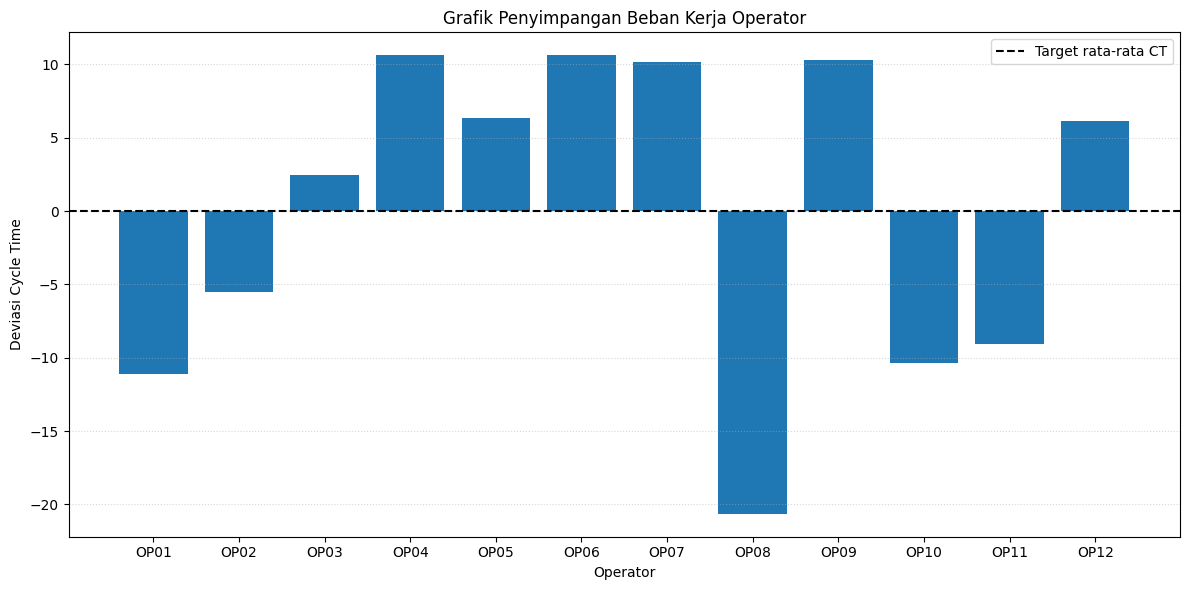

In [ ]:

# ==========================================
# ANALISIS PENYIMPANGAN BEBAN KERJA
# ==========================================

# Menghitung rata-rata CT
rata_ct = df['CT'].mean()

# Menghitung selisih CT terhadap rata-rata
df['Deviasi_CT'] = df['CT'] - rata_ct

# Menampilkan tabel deviasi
print("=== DEVIASI BEBAN KERJA OPERATOR ===")
print(df[['Operator', 'CT', 'Deviasi_CT']].round(3))

# Membuat grafik deviasi
plt.figure(figsize=(12, 6))

plt.bar(
    df['Operator'],
    df['Deviasi_CT']
)

plt.axhline(
    y=0,
    color='black',
    linestyle='--',
    label='Target rata-rata CT'
)

plt.title('Grafik Penyimpangan Beban Kerja Operator')
plt.xlabel('Operator')
plt.ylabel('Deviasi Cycle Time')
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:

# =====================================
# PERBANDINGAN BASELINE RPW VS GA
# =====================================

def calculate_metrics(result):

    loads = np.array(result["loads"], dtype=float)

    n = len(loads)
    total = loads.sum()
    ct_max = loads.max()
    ct_min = loads.min()
    mean = loads.mean()

    std = loads.std(ddof=0)
    cv = (std / mean) * 100

    efficiency = (
        total / (n * ct_max)
    ) * 100

    balance_delay = 100 - efficiency

    smoothness = np.sqrt(
        np.sum((ct_max - loads) ** 2)
    )

    return {
        "Total CT": total,
        "Rata-rata CT": mean,
        "Maksimum CT": ct_max,
        "Minimum CT": ct_min,
        "Range CT": ct_max - ct_min,
        "Standar Deviasi": std,
        "CV (%)": cv,
        "Line Efficiency (%)": efficiency,
        "Balance Delay (%)": balance_delay,
        "Smoothness Index": smoothness,
        "Total Skill": result["total_skill"]
    }


# Menghitung kedua metode
metrics_rpw = calculate_metrics(baseline_eval)
metrics_ga = calculate_metrics(best_global)

# Membuat tabel perbandingan
comparison = pd.DataFrame({
    "Baseline RPW": metrics_rpw,
    "Genetic Algorithm": metrics_ga
})

print("=== PERBANDINGAN RPW DAN GENETIC ALGORITHM ===")
display(comparison.round(3))

# Menghitung persentase perbaikan
print("\n=== PERUBAHAN HASIL OPTIMASI ===")

for metric in [
    "Standar Deviasi",
    "CV (%)",
    "Range CT",
    "Smoothness Index"
]:

    before = metrics_rpw[metric]
    after = metrics_ga[metric]

    if before != 0:
        improvement = (
            (before - after) / before
        ) * 100

        print(
            f"{metric}: {improvement:.2f}%"
        )

# Pemeriksaan takt time
print("\n=== VALIDASI TAKT TIME ===")
print("Baseline feasible:", baseline_eval["feasible"])
print("GA feasible:", best_global["feasible"])
print("Target CT:", TARGET_CT)


=== PERBANDINGAN RPW DAN GENETIC ALGORITHM ===


,Baseline RPW,Genetic Algorithm
Total CT,389.808,389.808
Rata-rata CT,32.484,32.484
Maksimum CT,43.108,43.108
Minimum CT,11.850,11.850
Range CT,31.258,31.258
Standar Deviasi,10.356,10.356
CV (%),31.881,31.881
Line Efficiency (%),75.355,75.355
Balance Delay (%),24.645,24.645
Smoothness Index,51.395,51.395



=== PERUBAHAN HASIL OPTIMASI ===
Standar Deviasi: 0.00%
CV (%): 0.00%
Range CT: 0.00%
Smoothness Index: 0.00%

=== VALIDASI TAKT TIME ===
Baseline feasible: True
GA feasible: True
Target CT: 45.0


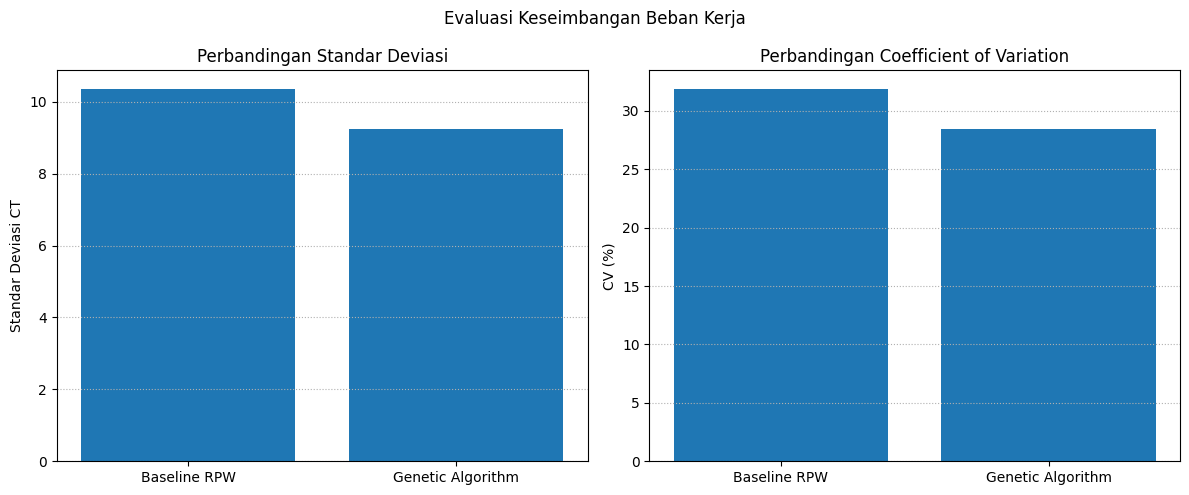

In [ ]:

# Grafik perbandingan keseimbangan beban kerja

labels = ["Baseline RPW", "Genetic Algorithm"]

std_values = [
    metrics_rpw["Standar Deviasi"],
    metrics_ga["Standar Deviasi"]
]

cv_values = [
    metrics_rpw["CV (%)"],
    metrics_ga["CV (%)"]
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(labels, std_values)
axes[0].set_title("Perbandingan Standar Deviasi")
axes[0].set_ylabel("Standar Deviasi CT")
axes[0].grid(axis='y', linestyle=':')

axes[1].bar(labels, cv_values)
axes[1].set_title("Perbandingan Coefficient of Variation")
axes[1].set_ylabel("CV (%)")
axes[1].grid(axis='y', linestyle=':')

plt.suptitle("Evaluasi Keseimbangan Beban Kerja")
plt.tight_layout()
plt.show()


In [ ]:
# =========================================================
# EKSPERIMEN TRADE-OFF KESEIMBANGAN CT DAN TOTAL SKILL
# Tidak mengubah fungsi atau parameter GA sebelumnya
# =========================================================

MIN_SKILL_TEST = [35, 36, 37]
SEEDS_TEST = range(1, 11)


# ---------------------------------------------------------
# 1. EVALUASI KHUSUS UNTUK EKSPERIMEN
# ---------------------------------------------------------

def evaluate_tradeoff(chrom, min_skill):

    groups = decode_chromosome(chrom)

    loads = np.array([
        sum(ct[a] for a in group)
        for group in groups
    ], dtype=float)

    max_ct = float(np.max(loads))
    min_ct = float(np.min(loads))
    mean_ct = float(np.mean(loads))
    std_ct = float(np.std(loads))

    cv = std_ct / mean_ct * 100 if mean_ct > 0 else 0

    ct_feasible = max_ct <= TARGET_CT + 1e-9
    ct_violation = max(0, max_ct - TARGET_CT)

    score_matrix = np.array([
        [
            sum(float(skill.loc[op, activity])
                for activity in group)
            for op in operators
        ]
        for group in groups
    ])

    row_ind, col_ind = linear_sum_assignment(-score_matrix)

    total_skill = int(
        score_matrix[row_ind, col_ind].sum()
    )

    skill_feasible = total_skill >= min_skill

    feasible = ct_feasible and skill_feasible

    fitness = (
        0 if ct_feasible else 1,
        round(ct_violation, 8),
        0 if skill_feasible else 1,
        max(0, min_skill - total_skill),
        round(std_ct, 8),
        round(max_ct, 8),
        -total_skill
    )

    return {
        "groups": groups,
        "loads": loads.tolist(),
        "max_ct": max_ct,
        "min_ct": min_ct,
        "mean_ct": mean_ct,
        "std_ct": std_ct,
        "cv": cv,
        "total_skill": total_skill,
        "feasible": feasible,
        "assignment": list(zip(row_ind, col_ind)),
        "fitness": fitness
    }


# ---------------------------------------------------------
# 2. FUNGSI GA KHUSUS EKSPERIMEN
# ---------------------------------------------------------

def run_ga_tradeoff(seed, min_skill):

    random.seed(seed)
    np.random.seed(seed)

    population = [baseline_chrom.copy()]

    while len(population) < POP_SIZE:
        population.append(random_chromosome())

    best_result = None

    for generation in range(GENERATIONS):

        evaluations = [
            evaluate_tradeoff(chrom, min_skill)
            for chrom in population
        ]

        sorted_indices = sorted(
            range(len(population)),
            key=lambda i: evaluations[i]["fitness"]
        )

        population = [
            population[i].copy()
            for i in sorted_indices
        ]

        evaluations = [
            evaluations[i]
            for i in sorted_indices
        ]

        current_best = evaluations[0]

        if (
            best_result is None
            or current_best["fitness"] < best_result["fitness"]
        ):
            best_result = current_best.copy()
            best_result["chromosome"] = population[0].copy()

        # Elitism
        new_population = [
            population[i].copy()
            for i in range(ELITE_SIZE)
        ]

        while len(new_population) < POP_SIZE:

            parent1 = selection(population, evaluations)
            parent2 = selection(population, evaluations)

            child1, child2 = crossover(parent1, parent2)

            child1 = mutation(child1)
            child2 = mutation(child2)

            new_population.append(child1)

            if len(new_population) < POP_SIZE:
                new_population.append(child2)

        population = new_population

    return best_result


# ---------------------------------------------------------
# 3. JALANKAN SEMUA SKENARIO SECARA OTOMATIS
# ---------------------------------------------------------

all_tradeoff_results = []

for min_skill in MIN_SKILL_TEST:

    print("\n" + "=" * 55)
    print(f"PENGUJIAN MINIMUM TOTAL SKILL: {min_skill}")
    print("=" * 55)

    for seed in SEEDS_TEST:

        result = run_ga_tradeoff(seed, min_skill)

        all_tradeoff_results.append({
            "Min_Skill": min_skill,
            "Seed": seed,
            "Max_CT": result["max_ct"],
            "Min_CT": result["min_ct"],
            "Std_Dev": result["std_ct"],
            "CV": result["cv"],
            "Total_Skill": result["total_skill"],
            "Feasible": result["feasible"],
            "Fitness": result["fitness"],
            "Result": result
        })

        print(
            f"Seed {seed:02d} | "
            f"Max CT: {result['max_ct']:.3f} | "
            f"Std: {result['std_ct']:.3f} | "
            f"CV: {result['cv']:.3f}% | "
            f"Skill: {result['total_skill']} | "
            f"Feasible: {result['feasible']}"
        )


# ---------------------------------------------------------
# 4. TABEL SELURUH HASIL 30 PENGUJIAN
# ---------------------------------------------------------

df_tradeoff = pd.DataFrame([
    {
        k: v for k, v in row.items()
        if k not in ["Fitness", "Result"]
    }
    for row in all_tradeoff_results
])

print("\nHASIL LENGKAP EKSPERIMEN TRADE-OFF")
display(df_tradeoff.round(3))


# ---------------------------------------------------------
# 5. RINGKASAN SETIAP SKENARIO
# ---------------------------------------------------------

summary_tradeoff = []

best_per_scenario = {}

for min_skill in MIN_SKILL_TEST:

    scenario = [
        row for row in all_tradeoff_results
        if row["Min_Skill"] == min_skill
    ]

    feasible_runs = [
        row for row in scenario
        if row["Feasible"]
    ]

    # Pilih hasil terbaik yang memenuhi seluruh batasan
    if feasible_runs:
        best = min(
            feasible_runs,
            key=lambda x: x["Fitness"]
        )
    else:
        best = min(
            scenario,
            key=lambda x: x["Fitness"]
        )

    best_per_scenario[min_skill] = best

    summary_tradeoff.append({
        "Minimum_Skill": min_skill,
        "Best_Seed": best["Seed"],
        "Max_CT": best["Max_CT"],
        "Min_CT": best["Min_CT"],
        "Std_Dev": best["Std_Dev"],
        "CV": best["CV"],
        "Total_Skill": best["Total_Skill"],
        "Feasible_Runs": len(feasible_runs),
        "Rata2_Std_Dev": np.mean([
            row["Std_Dev"] for row in scenario
        ])
    })

df_summary_tradeoff = pd.DataFrame(summary_tradeoff)

print("\nRINGKASAN PERBANDINGAN SKENARIO")
display(df_summary_tradeoff.round(3))


# ---------------------------------------------------------
# 6. PILIH SOLUSI TERBAIK DARI SELURUH SKENARIO
# ---------------------------------------------------------

all_feasible = [
    row for row in all_tradeoff_results
    if row["Feasible"]
]

if all_feasible:

    best_tradeoff = min(
        all_feasible,
        key=lambda x: (
            x["Std_Dev"],
            x["Max_CT"],
            -x["Total_Skill"]
        )
    )

    best_tradeoff_result = best_tradeoff["Result"]

    print("\n" + "=" * 55)
    print("SOLUSI TERBAIK EKSPERIMEN TRADE-OFF")
    print("=" * 55)

    print("Batas minimum skill:", best_tradeoff["Min_Skill"])
    print("Seed terbaik:", best_tradeoff["Seed"])
    print("Maximum CT:", round(best_tradeoff["Max_CT"], 3))
    print("Minimum CT:", round(best_tradeoff["Min_CT"], 3))
    print("Standar deviasi:", round(best_tradeoff["Std_Dev"], 3))
    print("CV:", round(best_tradeoff["CV"], 3), "%")
    print("Total Skill:", best_tradeoff["Total_Skill"])
    print("Feasible:", best_tradeoff["Feasible"])

    # Tampilkan assignment terbaik
    df_best_tradeoff = create_assignment_table(
        best_tradeoff_result
    )

    print("\nASSIGNMENT OPERATOR TERBAIK")
    display(df_best_tradeoff)

else:

    print("Tidak ditemukan solusi yang memenuhi seluruh batasan.")


PENGUJIAN MINIMUM TOTAL SKILL: 35
Seed 01 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 02 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 03 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 04 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 05 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 06 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 07 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 08 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 09 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 10 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True

PENGUJIAN MINIMUM TOTAL SKILL: 36
Seed 01 | Max CT: 43.108 | Std: 9.238 | CV: 28.438% | Skill: 36 | Feasible: True
Seed 02 | Max CT: 43.108 | Std: 9.238 |

,Min_Skill,Seed,Max_CT,Min_CT,Std_Dev,CV,Total_Skill,Feasible
0,35,1,43.108,21.371,9.238,28.438,36,True
1,35,2,43.108,21.371,9.238,28.438,36,True
2,35,3,43.108,21.371,9.238,28.438,36,True
3,35,4,43.108,21.371,9.238,28.438,36,True
4,35,5,43.108,21.371,9.238,28.438,36,True
5,35,6,43.108,21.371,9.238,28.438,36,True
6,35,7,43.108,21.371,9.238,28.438,36,True
7,35,8,43.108,21.371,9.238,28.438,36,True
8,35,9,43.108,21.371,9.238,28.438,36,True
9,35,10,43.108,21.371,9.238,28.438,36,True



RINGKASAN PERBANDINGAN SKENARIO


,Minimum_Skill,Best_Seed,Max_CT,Min_CT,Std_Dev,CV,Total_Skill,Feasible_Runs,Rata2_Std_Dev
0,35,1,43.108,21.371,9.238,28.438,36,10,9.238
1,36,1,43.108,21.371,9.238,28.438,36,10,9.238
2,37,1,43.108,11.850,10.356,31.881,37,10,10.356



SOLUSI TERBAIK EKSPERIMEN TRADE-OFF
Batas minimum skill: 35
Seed terbaik: 1
Maximum CT: 43.108
Minimum CT: 21.371
Standar deviasi: 9.238
CV: 28.438 %
Total Skill: 36
Feasible: True

ASSIGNMENT OPERATOR TERBAIK


,Operator,Aktivitas,Total_CT_s,Skill,Skor_Skill
0,OP01,SW15,21.371,2,2
1,OP02,SW02 - SW03,26.984,3 - 2,5
2,OP03,SW06,22.006,2,2
3,OP04,SW01,43.108,3,3
4,OP05,SW04 - SW05,38.810,3 - 2,5
5,OP06,SW09,43.106,2,2
6,OP07,SW10,42.649,3,3
7,OP08,SW07 - SW08,24.795,2 - 3,5
8,OP09,SW11,42.757,2,2
9,OP10,SW13,22.155,3,3
